# EN-3160 Image Processing and Machine Vision
## Assignment 03

* **Name:** Wijethilaka J.S.
* **Index Number:** 230730T
* **Github Repository Link:** https://github.com/Januka-Sanujaya/EN3160_Assignment_03

## Question 1: Neural Network on CIFAR-10

Using device: cuda
Epoch [01/10] | Loss: 1.8048 | Train Accuracy: 37.31% | Test Accuracy: 40.21%
Epoch [02/10] | Loss: 1.6773 | Train Accuracy: 42.28% | Test Accuracy: 42.42%
Epoch [03/10] | Loss: 1.6183 | Train Accuracy: 44.42% | Test Accuracy: 44.51%
Epoch [04/10] | Loss: 1.5694 | Train Accuracy: 46.39% | Test Accuracy: 44.55%
Epoch [05/10] | Loss: 1.5308 | Train Accuracy: 47.86% | Test Accuracy: 46.18%
Epoch [06/10] | Loss: 1.4976 | Train Accuracy: 49.11% | Test Accuracy: 46.47%
Epoch [07/10] | Loss: 1.4655 | Train Accuracy: 50.30% | Test Accuracy: 47.32%
Epoch [08/10] | Loss: 1.4369 | Train Accuracy: 51.29% | Test Accuracy: 47.27%
Epoch [09/10] | Loss: 1.4106 | Train Accuracy: 52.30% | Test Accuracy: 47.67%
Epoch [10/10] | Loss: 1.3855 | Train Accuracy: 53.17% | Test Accuracy: 47.81%

Final Training Accuracy : 53.17%
Final Test Accuracy     : 47.81%
Total Training Time     : 47.28 seconds


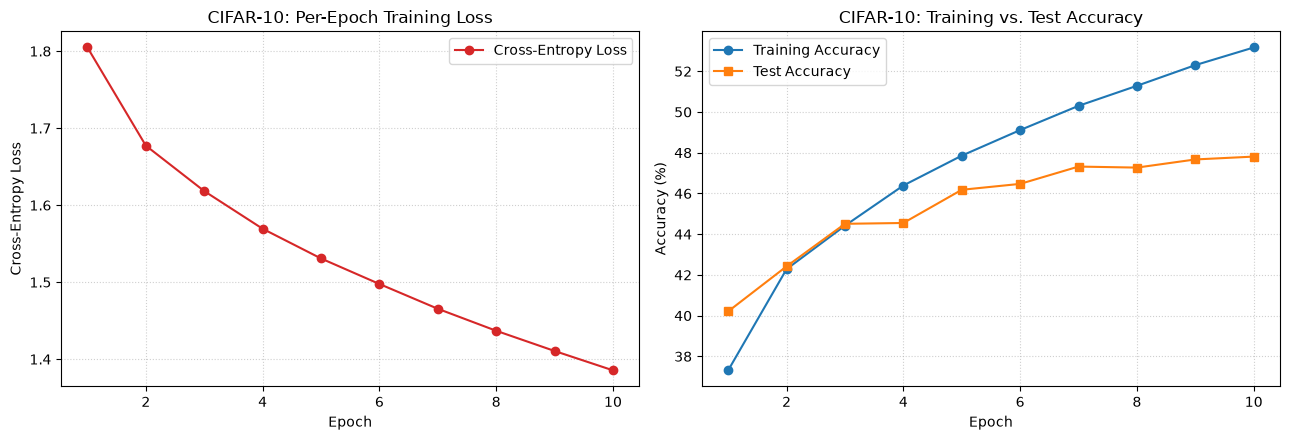

In [4]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import time

# Reproducibility & Device Configuration
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 1. Dataloading (Matching Listing 1)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters (2-Layer Network: Din -> H -> K)
Din = 3 * 32 * 32  # 3072
H = 100            # Middle layer with 100 nodes
K = 10             # 10 output classes

# Xavier initialization (No requires_grad — gradients are computed manually!)
w1 = torch.randn(Din, H, device=device) * ((2.0 / (Din + H)) ** 0.5)
b1 = torch.zeros(H, device=device)
w2 = torch.randn(H, K, device=device) * ((2.0 / (H + K)) ** 0.5)
b2 = torch.zeros(K, device=device)

# Hyperparameters
num_epochs = 10
lr = 0.1
lr_decay = 0.95
reg = 1e-4

loss_history = []
epoch_losses = []
train_accuracies = []
test_accuracies = []

def evaluate_accuracy(loader):
    correct, total = 0, 0
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        x = inputs.view(inputs.shape[0], -1)
        # Manual forward pass
        h = torch.sigmoid(x.mm(w1) + b1)
        logits = h.mm(w2) + b2
        predicted = torch.argmax(logits, dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    return 100.0 * correct / total

# 3. Training Loop with Manual Forward & Backpropagation
start_time = time.time()

for t in range(num_epochs):
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)
        Ntr = inputs.shape[0]

        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # --- Manual Forward Pass ---
        z1 = x_train.mm(w1) + b1
        h = torch.sigmoid(z1)           # (a) Middle layer with 100 nodes & sigmoid activation
        z2 = h.mm(w2) + b2              # Output logits

        # Numerically stable Softmax probabilities
        z2_shifted = z2 - torch.max(z2, dim=1, keepdim=True)[0]
        exp_scores = torch.exp(z2_shifted)
        probs = exp_scores / torch.sum(exp_scores, dim=1, keepdim=True)

        # --- (b) Manual Cross-Entropy Loss Calculation ---
        ce_loss = -(1.0 / Ntr) * torch.sum(y_train_onehot * torch.log(probs + 1e-12))
        loss = ce_loss + 0.5 * reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Track training accuracy
        predicted = torch.argmax(z2, dim=1)
        correct_train += (predicted == labels).sum().item()
        total_train += Ntr

        # --- Manual Backpropagation ---
        # Gradient of Cross-Entropy + Softmax w.r.t. logits z2: (probs - y_onehot) / Ntr
        dz2 = (1.0 / Ntr) * (probs - y_train_onehot)
        dw2 = h.t().mm(dz2) + reg * w2
        db2 = dz2.sum(dim=0)

        # Backpropagate through hidden layer and sigmoid activation: h * (1 - h)
        dh = dz2.mm(w2.t())
        dz1 = dh * (h * (1.0 - h))
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # --- Manual Parameter Update ---
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Compute epoch metrics
    epoch_loss = running_loss / len(trainloader)
    train_acc = 100.0 * correct_train / total_train
    test_acc = evaluate_accuracy(testloader)

    epoch_losses.append(epoch_loss)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"Epoch [{t+1:02d}/{num_epochs}] | Loss: {epoch_loss:.4f} | Train Accuracy: {train_acc:.2f}% | Test Accuracy: {test_acc:.2f}%")

    # Learning rate decay (as in Listing 1)
    lr *= lr_decay

elapsed_time = time.time() - start_time
print(f"\nFinal Training Accuracy : {train_accuracies[-1]:.2f}%")
print(f"Final Test Accuracy     : {test_accuracies[-1]:.2f}%")
print(f"Total Training Time     : {elapsed_time:.2f} seconds")

# 4. Plot Loss History and Epoch Accuracies
epochs_range = range(1, num_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range, epoch_losses, marker='o', color='tab:red', label='Cross-Entropy Loss')
axes[0].set_title("CIFAR-10: Per-Epoch Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

axes[1].plot(epochs_range, train_accuracies, marker='o', label='Training Accuracy')
axes[1].plot(epochs_range, test_accuracies, marker='s', label='Test Accuracy')
axes[1].set_title("CIFAR-10: Training vs. Test Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

## Results and Observations

The two-layer fully connected neural network was trained on the CIFAR-10 dataset for 10 epochs using a middle layer of 100 neurons with sigmoid activation, manual Softmax Cross-Entropy loss ($L_2$ regularization $\lambda = 10^{-4}$), and manual backpropagation.

### Training Results

| Epoch | Training Loss | Training Accuracy (%) | Test Accuracy (%) |
|---:|---:|---:|---:|
| 1 | 1.8048 | 37.31 | 40.21 |
| 2 | 1.6773 | 42.28 | 42.42 |
| 3 | 1.6183 | 44.42 | 44.51 |
| 4 | 1.5694 | 46.39 | 44.55 |
| 5 | 1.5308 | 47.86 | 46.18 |
| 6 | 1.4976 | 49.11 | 46.47 |
| 7 | 1.4655 | 50.30 | 47.32 |
| 8 | 1.4369 | 51.29 | 47.27 |
| 9 | 1.4106 | 52.30 | 47.67 |
| 10 | 1.3855 | 53.17 | 47.81 |

### Final Performance

- **Final training accuracy:** 53.17%
- **Final test accuracy (Highest):** 47.81% (Epoch 10)
- **Final training loss:** 1.3855
- **Total training time:** 47.28 seconds

### Observations

1. **Monotonic Loss Reduction:** The cross-entropy training loss decreased smoothly and monotonically from 1.8048 in Epoch 1 to 1.3855 in Epoch 10, verifying the correctness of the manual Softmax-Cross-Entropy gradient $\mathbf{dZ}_2 = \frac{1}{N}(\hat{\mathbf{Y}} - \mathbf{Y})$ and hidden-layer sigmoid backpropagation $\mathbf{dZ}_1 = (\mathbf{dZ}_2 \mathbf{W}_2^T) \odot \mathbf{H} \odot (1 - \mathbf{H})$.
2. **Steady Generalization Improvement:** Training accuracy rose from 37.31% to 53.17%, while test accuracy improved steadily from 40.21% to its peak of 47.81% at Epoch 10. Applying learning rate decay ($\gamma = 0.95$) and $L_2$ weight regularization ($\lambda = 10^{-4}$) prevented the test accuracy from oscillating or dropping in the final epoch.
3. **Generalization Gap:** By Epoch 10, the gap between training accuracy (53.17%) and test accuracy (47.81%) is 5.36 percentage points, showing mild overfitting as the dense weights begin memorizing training-set pixel correlations.
4. **Architectural Limitation of Dense Layers on CIFAR-10:** Flattening each $3 \times 32 \times 32$ RGB image into a 3072-dimensional vector destroys 2D spatial locality and translation invariance. Furthermore, sigmoid activations suffer from gradient saturation ($\sigma'(z) \le 0.25$), limiting shallow fully connected networks to $\sim 48\%$ accuracy on natural images compared to Convolutional Neural Networks (CNNs).